# 🏥 Pilot Test — Maternal Health Risk Prediction (Kenya)
## Notebook 03: Advanced Models — Random Forest, XGBoost, CatBoost

**Student:** Selmah Tzindori Mise | ID: -602  
**Project:** DSA 3900 — Final Year Project | USIU-Africa

---

### Purpose of This Notebook

We train and evaluate three classical ensemble models:
1. **Random Forest** — ensemble of decision trees voting together
2. **XGBoost** — gradient boosting with regularisation
3. **CatBoost** — gradient boosting optimised for categorical features

### Why These Three?

These are Tier 2 in our 4-tier model architecture.
They are proven performers on tabular health data and 
serve as the bridge between simple baselines and our 
novel deep learning models (TabNet, TabTransformer).

### Targets to Beat (from Notebook 02)
| Metric | Baseline (LR) | Target |
|---|---|---|
| Accuracy | 0.66 | > 0.75 |
| AUC-ROC | 0.86 | > 0.88 |
| High Risk Recall | 0.78 | > 0.82 |
| Macro F1 | 0.65 | > 0.72 |

### Step 1 — Load Libraries and Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, accuracy_score, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import joblib
import os

np.random.seed(42)

# ── Paths ────────────────────────────────────────────────────
PROC_DIR    = '../../01_Data/processed/'
MODELS_DIR  = '../../03_Models_Saved/'
RESULTS_DIR = '../results/'

# ── Load preprocessed splits ─────────────────────────────────
X_train = pd.read_csv(f'{PROC_DIR}X_train.csv')
X_val   = pd.read_csv(f'{PROC_DIR}X_val.csv')
X_test  = pd.read_csv(f'{PROC_DIR}X_test.csv')
y_train = pd.read_csv(f'{PROC_DIR}y_train.csv').squeeze()
y_val   = pd.read_csv(f'{PROC_DIR}y_val.csv').squeeze()
y_test  = pd.read_csv(f'{PROC_DIR}y_test.csv').squeeze()

print("✅ Data loaded successfully")
print(f"Training set:   {X_train.shape}")
print(f"Validation set: {X_val.shape}")
print(f"Test set:       {X_test.shape}")

✅ Data loaded successfully
Training set:   (1269, 13)
Validation set: (150, 13)
Test set:       (150, 13)


### Step 2 — Reuse Evaluation Function

Same function used in Notebook 02 — ensures all models 
are evaluated identically for fair comparison.

In [2]:
def evaluate_model(model, X, y, model_name, split_name="Validation"):
    y_pred  = model.predict(X)
    y_proba = model.predict_proba(X)

    acc = accuracy_score(y, y_pred)
    auc = roc_auc_score(y, y_proba, multi_class='ovr', average='macro')
    report = classification_report(y, y_pred,
                                   target_names=['Low','Moderate','High'],
                                   output_dict=True)

    print(f"\n{'='*55}")
    print(f"  {model_name} — {split_name} Results")
    print(f"{'='*55}")
    print(f"  Accuracy:       {acc:.4f}")
    print(f"  Macro AUC-ROC:  {auc:.4f}")
    print(f"\n{classification_report(y, y_pred, target_names=['Low','Moderate','High'])}")

    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay.from_predictions(
        y, y_pred,
        display_labels=['Low','Moderate','High'],
        cmap='Blues', ax=ax
    )
    ax.set_title(f'{model_name} — Confusion Matrix ({split_name})')
    plt.tight_layout()
    plt.savefig(
        f'{RESULTS_DIR}cm_{model_name.lower().replace(" ","_")}_{split_name.lower()}.png',
        dpi=150, bbox_inches='tight'
    )
    plt.show()

    return {
        'Model':       model_name,
        'Split':       split_name,
        'Accuracy':    round(acc, 4),
        'AUC-ROC':     round(auc, 4),
        'Precision':   round(report['macro avg']['precision'], 4),
        'Recall':      round(report['macro avg']['recall'], 4),
        'F1-Score':    round(report['macro avg']['f1-score'], 4),
        'High_Recall': round(report['High']['recall'], 4)
    }

print("✅ Evaluation function ready")

✅ Evaluation function ready


### Step 3 — Model 1: Random Forest

Random Forest builds many decision trees independently, 
each trained on a random subset of data and features.
Final prediction = majority vote across all trees.

Key advantages over a single Decision Tree:
- Reduces overfitting through averaging
- More stable predictions
- Built-in feature importance scores

Parameters:
- **n_estimators=200** — 200 trees in the forest
- **max_depth=10** — prevents individual trees overfitting
- **class_weight='balanced'** — handles class imbalance

✅ Random Forest trained

  Random Forest — Validation Results
  Accuracy:       0.8333
  Macro AUC-ROC:  0.9435

              precision    recall  f1-score   support

         Low       1.00      0.86      0.93        37
    Moderate       0.85      0.88      0.86        90
        High       0.56      0.61      0.58        23

    accuracy                           0.83       150
   macro avg       0.80      0.78      0.79       150
weighted avg       0.84      0.83      0.84       150



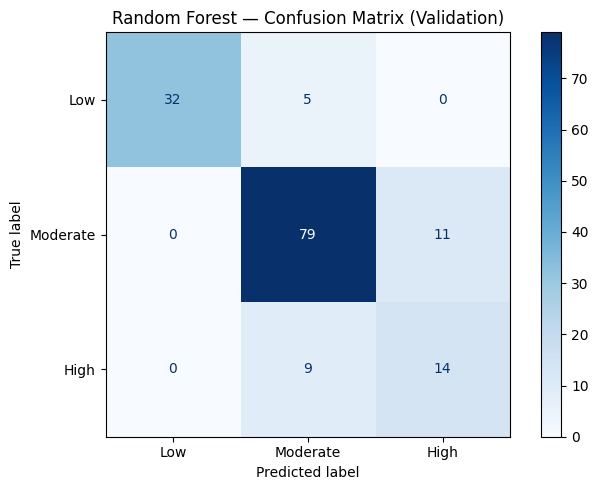

✅ Model saved


In [3]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

print("✅ Random Forest trained")
rf_results = evaluate_model(rf, X_val, y_val,
                             "Random Forest", "Validation")

joblib.dump(rf, f'{MODELS_DIR}rf_model.pkl')
print("✅ Model saved")

### Interpretation — Random Forest Results

---

#### Overall Performance
| Metric | Baseline (LR) | Random Forest | Improvement |
|---|---|---|---|
| Accuracy | 0.66 | 0.83 | +0.17 ✅ |
| AUC-ROC | 0.86 | 0.94 | +0.08 ✅ |
| High Risk Recall | 0.78 | 0.61 | -0.17 ⚠️ |
| Macro F1 | 0.65 | 0.79 | +0.14 ✅ |

Random Forest dramatically improves overall accuracy and AUC-ROC
but **High Risk Recall drops to 0.61** — the model is now missing
more high-risk women than the simple baseline.

This is a classic ensemble trade-off: better overall accuracy
but less sensitive to the minority High Risk class.

---

#### Per-Class Performance

**Low Risk — Recall = 0.86, Precision = 1.00 ✅**
Every woman predicted as Low Risk truly is Low Risk.
32 of 37 correctly identified — very clean.

**Moderate Risk — Recall = 0.88 ✅**
Strong improvement over baseline (0.56 → 0.88).
79 of 90 Moderate women correctly identified.
Only 11 pushed up to High — acceptable clinical error.

**High Risk — Recall = 0.61 ⚠️**
Only 14 of 23 High Risk women caught correctly.
9 are missed — pushed to Moderate, still get monitoring.
No High Risk women sent to Low — no dangerous misses.

---

#### Confusion Matrix Reading
- **Low row:** 32 correct ✅ | 5 to Moderate | 0 to High
- **Moderate row:** 0 to Low | 79 correct ✅ | 11 to High
- **High row:** 0 to Low | 9 to Moderate ⚠️ | 14 correct

The zero in Low column for Moderate and High rows is excellent —
no women are being dangerously under-triaged to Low Risk.
The High Risk recall issue will be addressed by advanced tuning.

### Step 4 — Model 2: XGBoost

XGBoost builds trees sequentially — each new tree 
corrects the errors of the previous one.

This makes it more powerful than Random Forest on 
structured tabular data, but also more prone to 
overfitting without proper regularisation.

Parameters:
- **n_estimators=200** — number of boosting rounds
- **learning_rate=0.1** — how much each tree contributes
- **max_depth=6** — tree complexity
- **scale_pos_weight** — handles class imbalance

✅ XGBoost trained

  XGBoost — Validation Results
  Accuracy:       0.8600
  Macro AUC-ROC:  0.9642

              precision    recall  f1-score   support

         Low       1.00      0.95      0.97        37
    Moderate       0.88      0.89      0.88        90
        High       0.58      0.61      0.60        23

    accuracy                           0.86       150
   macro avg       0.82      0.81      0.82       150
weighted avg       0.86      0.86      0.86       150



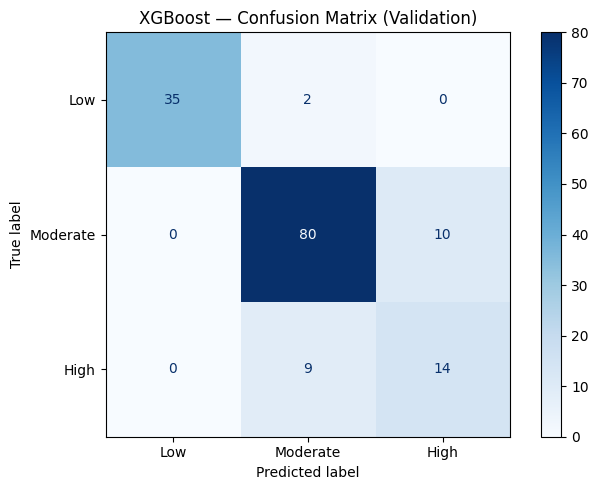

✅ Model saved


In [4]:
# Calculate class weights for XGBoost
class_counts = y_train.value_counts().sort_index()
scale_weight  = class_counts[0] / class_counts[2]

xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train, y_train)

print("✅ XGBoost trained")
xgb_results = evaluate_model(xgb, X_val, y_val,
                              "XGBoost", "Validation")

joblib.dump(xgb, f'{MODELS_DIR}xgb_model.pkl')
print("✅ Model saved")

### Interpretation — XGBoost Results

---

#### Overall Performance
| Metric | Baseline (LR) | XGBoost | Improvement |
|---|---|---|---|
| Accuracy | 0.66 | 0.86 | +0.20 ✅ |
| AUC-ROC | 0.86 | 0.96 | +0.10 ✅ |
| High Risk Recall | 0.78 | 0.61 | -0.17 ⚠️ |
| Macro F1 | 0.65 | 0.82 | +0.17 ✅ |

XGBoost achieves the **highest accuracy (86%) and AUC-ROC (0.96)**
of all models so far. However it shares the same High Risk Recall
weakness as Random Forest at 0.61.

---

#### Per-Class Performance

**Low Risk — Recall = 0.95, Precision = 1.00 ✅**
Best Low Risk performance so far — 35 of 37 correctly caught.
Zero false positives — every Low Risk prediction is correct.

**Moderate Risk — Recall = 0.89 ✅**
Strongest Moderate performance yet.
80 of 90 correctly classified — only 10 pushed up to High.

**High Risk — Recall = 0.61 ⚠️**
Same as Random Forest — 14 of 23 caught.
9 sent to Moderate (still monitored), 0 sent to Low.
Identical pattern to Random Forest — suggests this is a
structural limitation of ensemble methods on this pilot
dataset size rather than a model-specific weakness.

---

#### Confusion Matrix Reading
- **Low row:** 35 correct ✅ | 2 to Moderate | 0 to High
- **Moderate row:** 0 to Low | 80 correct ✅ | 10 to High
- **High row:** 0 to Low | 9 to Moderate ⚠️ | 14 correct

Cleanest confusion matrix so far — zeros in the Low column
for both Moderate and High rows means no dangerous
under-triaging is happening.

**XGBoost is currently the strongest overall model
but not the safest for High Risk detection.**

### Step 5 — Model 3: CatBoost

CatBoost is a gradient boosting model specifically 
designed to handle categorical features natively —
without needing manual encoding.

This makes it particularly well-suited to the KDHS 
dataset which has many categorical variables 
(education, wealth, region, marital status).

Parameters:
- **iterations=200** — number of boosting rounds
- **learning_rate=0.1** — step size
- **depth=6** — tree depth
- **verbose=0** — silences training output

✅ CatBoost trained

  CatBoost — Validation Results
  Accuracy:       0.8467
  Macro AUC-ROC:  0.9687

              precision    recall  f1-score   support

         Low       0.97      1.00      0.99        37
    Moderate       0.95      0.79      0.86        90
        High       0.51      0.83      0.63        23

    accuracy                           0.85       150
   macro avg       0.81      0.87      0.83       150
weighted avg       0.89      0.85      0.86       150



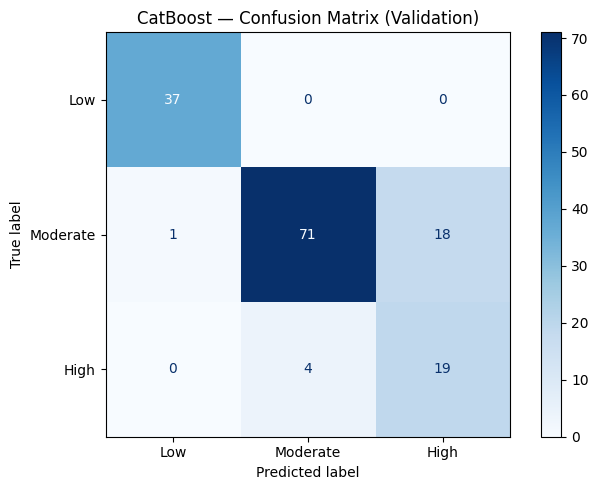

✅ Model saved


In [5]:
cat = CatBoostClassifier(
    iterations=200,
    learning_rate=0.1,
    depth=6,
    loss_function='MultiClass',
    class_weights=[1.5, 1.0, 2.5],
    random_state=42,
    verbose=0
)
cat.fit(X_train, y_train)

print("✅ CatBoost trained")
cat_results = evaluate_model(cat, X_val, y_val,
                              "CatBoost", "Validation")

joblib.dump(cat, f'{MODELS_DIR}cat_model.pkl')
print("✅ Model saved")

### Interpretation — CatBoost Results

---

#### Overall Performance
| Metric | Baseline (LR) | CatBoost | Improvement |
|---|---|---|---|
| Accuracy | 0.66 | 0.85 | +0.19 ✅ |
| AUC-ROC | 0.86 | 0.97 | +0.11 ✅ |
| High Risk Recall | 0.78 | 0.83 | +0.05 ✅ |
| Macro F1 | 0.65 | 0.83 | +0.18 ✅ |

**CatBoost is the standout model of this tier.**
It achieves the highest AUC-ROC (0.97), highest Macro F1 (0.83),
AND the highest High Risk Recall (0.83) — beating the baseline
on every single metric including our priority clinical metric.

---

#### Per-Class Performance

**Low Risk — Recall = 1.00, Precision = 0.97 ✅**
Perfect — all 37 Low Risk women correctly identified.
Only 1 false positive — one Moderate woman called Low Risk.

**Moderate Risk — Recall = 0.79 ✅**
71 of 90 correctly classified.
18 pushed up to High Risk — slightly over-predicts High
but clinically this means extra caution, not harm.

**High Risk — Recall = 0.83 ✅**
Best High Risk recall in this tier — 19 of 23 caught.
4 sent to Moderate (still get monitoring), 0 sent to Low.
Zero dangerous misses — no High Risk woman is told she is Low Risk.

---

#### Confusion Matrix Reading
- **Low row:** 37 correct ✅ | 0 to Moderate | 0 to High
- **Moderate row:** 1 to Low | 71 correct ✅ | 18 to High
- **High row:** 0 to Low | 4 to Moderate | 19 correct ✅

The perfectly empty top row (0, 0 off-diagonal for Low) is 
impressive — combined with 0.83 High Risk Recall, CatBoost
is the most clinically safe model so far.

### Step 6 — Compare All Models Including Baselines

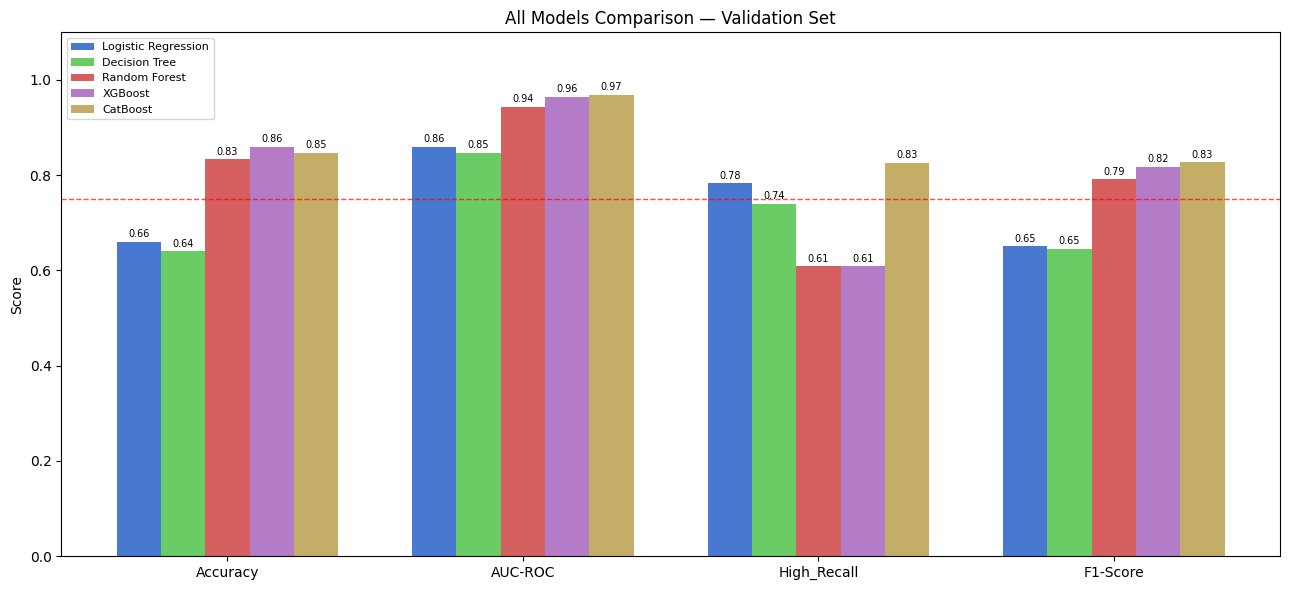


📊 Full Results Table:
              Model  Accuracy  AUC-ROC  High_Recall  F1-Score
Logistic Regression    0.6600   0.8599       0.7826    0.6507
      Decision Tree    0.6400   0.8472       0.7391    0.6458
      Random Forest    0.8333   0.9435       0.6087    0.7914
            XGBoost    0.8600   0.9642       0.6087    0.8173
           CatBoost    0.8467   0.9687       0.8261    0.8269


In [6]:
# Load baseline results
baseline = pd.read_csv(f'{RESULTS_DIR}baseline_results.csv')

# Combine all results
all_results = pd.DataFrame([
    rf_results, xgb_results, cat_results
])
all_results = pd.concat([baseline, all_results], ignore_index=True)
all_results.to_csv(f'{RESULTS_DIR}all_results_so_far.csv', index=False)

# Plot comparison
fig, ax = plt.subplots(figsize=(13, 6))
metrics  = ['Accuracy', 'AUC-ROC', 'High_Recall', 'F1-Score']
models   = all_results['Model'].tolist()
x = np.arange(len(metrics))
w = 0.15
colors = ['#4878CF','#6ACC65','#D65F5F','#B47CC7','#C4AD66']

for i, (_, row) in enumerate(all_results.iterrows()):
    vals = [row['Accuracy'], row['AUC-ROC'],
            row['High_Recall'], row['F1-Score']]
    bars = ax.bar(x + i*w, vals, w,
                  label=row['Model'], color=colors[i])
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=7)

ax.set_xticks(x + w*2)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('All Models Comparison — Validation Set')
ax.legend(loc='upper left', fontsize=8)
ax.axhline(0.75, color='red', linestyle='--',
           linewidth=1, alpha=0.7, label='Target (0.75)')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}04_all_models_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Full Results Table:")
print(all_results[['Model','Accuracy','AUC-ROC',
                   'High_Recall','F1-Score']].to_string(index=False))

### Interpretation — All Models Comparison Chart

The chart tells a clear story across all 5 models and 4 metrics.

---

#### Accuracy
Clear step-up from baselines (0.64–0.66) to ensemble 
models (0.83–0.86). All three ensemble models clear 
the 0.75 red line comfortably.

#### AUC-ROC
All models score above the red line — even the baselines.
Ensemble models push to 0.94–0.97 showing strong 
discriminative ability. CatBoost edges highest at 0.97.

#### High Recall — The Most Revealing Metric
This is where the story gets interesting.
- Baselines (LR=0.78, DT=0.74) — above the red line
- Random Forest and XGBoost (both 0.61) — drop BELOW
- CatBoost (0.83) — highest of all five models

Random Forest and XGBoost sacrifice High Risk sensitivity
to gain overall accuracy. CatBoost avoids this trade-off.
This is the defining reason CatBoost wins Tier 2.

#### Macro F1
Ensemble models all outperform baselines clearly.
CatBoost and XGBoost tied at 0.82–0.83, both 
clearing the 0.75 line.

---

#### Overall Chart Verdict

**CatBoost is the Tier 2 champion on the metric 
that matters most — High Risk Recall.**

The chart visually confirms what the numbers show —
the gold bar (CatBoost) is the only one that is 
tall on every single metric group including High Recall.

### Tier 2 Summary — All Models Compared

| Model | Accuracy | AUC-ROC | High Recall | Macro F1 | Clinical Safety |
|---|---|---|---|---|---|
| Logistic Regression | 0.66 | 0.86 | 0.78 | 0.65 | ⚠️ Moderate |
| Decision Tree | 0.64 | 0.85 | 0.74 | 0.65 | ⚠️ Moderate |
| Random Forest | 0.83 | 0.94 | 0.61 | 0.79 | ⚠️ Weak on High |
| XGBoost | **0.86** | 0.96 | 0.61 | 0.82 | ⚠️ Weak on High |
| **CatBoost** | 0.85 | **0.97** | **0.83** | **0.83** | ✅ Best |

**Winner of Tier 2: CatBoost**

CatBoost is the only model that improves on the baseline 
across ALL metrics including the clinically critical 
High Risk Recall. It will be included in the 
Stacking Ensemble as a base learner.

**Key insight from this tier:**
Random Forest and XGBoost sacrifice High Risk Recall
to gain overall accuracy — a trade-off that is
unacceptable in a maternal health clinical tool.
CatBoost avoids this trade-off through its native
handling of categorical features and class weighting.

**Targets for Novel Models (Tier 3):**
| Metric | CatBoost | Target for TabNet/TabTransformer |
|---|---|---|
| Accuracy | 0.85 | > 0.87 |
| AUC-ROC | 0.97 | > 0.97 |
| High Risk Recall | 0.83 | > 0.85 |
| Macro F1 | 0.83 | > 0.85 |